# Account Risk Scoring Landscape

Descriptive views of the latest account scoring output: coverage, high-risk probabilities, churn/loss components, account importance, rep priority, and model drivers. This notebook reads saved outputs only; it does not fit or change the classifiers.

The supplied data ends on 31 August 2018. These are scores for that historical snapshot, not live/current customer scores. Probabilities are forecasts of the next eligible monthly snapshot. Accounts with fewer than three orders in the previous 18 months are shown as insufficient data and are not treated as low risk.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / 'data' / 'raw').is_dir() and (candidate / 'outputs').is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not find project root containing data/raw and outputs.')

OUTPUT_DIR = project_root / 'outputs'
SCORE_PATH = OUTPUT_DIR / 'current_account_priority_queue.csv'
GLOBAL_IMPORTANCE_PATH = OUTPUT_DIR / 'high_risk_feature_importance.csv'
LOCAL_CONTRIBUTION_PATH = OUTPUT_DIR / 'current_account_feature_contributions.csv'
HIGH_RISK_THRESHOLD = 0.50

if not SCORE_PATH.exists():
    raise FileNotFoundError(f'{SCORE_PATH} not found. Run train_high_risk_classifier.ipynb first.')

scores = pd.read_csv(SCORE_PATH, parse_dates=['snapshot_month'])
eligible = scores.loc[scores['eligible'].eq(1)].copy()
not_scored = scores.loc[scores['eligible'].eq(0)].copy()
snapshot = scores['snapshot_month'].max()
eligible['high_risk_flag'] = eligible['high_risk_probability'] >= HIGH_RISK_THRESHOLD
eligible['risk_band'] = pd.cut(
    eligible['high_risk_probability'],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.000001],
    labels=['0-20%', '20-40%', '40-60%', '60-80%', '80-100%'],
    include_lowest=True,
)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold'})
print(f'Scoring snapshot: {snapshot:%d %B %Y}')
print(f'All accounts: {len(scores):,} | Scored: {len(eligible):,} | Insufficient data: {len(not_scored):,}')
print(f'High-risk threshold: {HIGH_RISK_THRESHOLD:.0%}')

Scoring snapshot: 31 August 2018
All accounts: 14,989 | Scored: 9,577 | Insufficient data: 5,412
High-risk threshold: 50%


## Snapshot summary
Use the displayed table as a compact set of portfolio-level descriptive statistics. The high-risk flag is a presentation cut at 0.50; the underlying probability is continuous and should remain visible.

In [2]:
summary = pd.DataFrame({
    'Measure': [
        'All accounts', 'Scored accounts', 'Insufficient data',
        'Scored high-risk at threshold', 'Scored high-risk share',
        'Median high-risk probability', 'Median churn probability',
        'Median loss probability', 'Median account importance percentile',
    ],
    'Value': [
        len(scores), len(eligible), len(not_scored),
        int(eligible['high_risk_flag'].sum()), eligible['high_risk_flag'].mean(),
        eligible['high_risk_probability'].median(), eligible['churn_probability'].median(),
        eligible['loss_probability'].median(), eligible['account_importance_score'].median(),
    ],
})
display(summary)
print('High-risk flag counts:')
display(eligible['high_risk_flag'].map({True: 'At/above threshold', False: 'Below threshold'}).value_counts().rename_axis('Group').to_frame('Accounts'))

,Measure,Value
0,All accounts,14989.000000
1,Scored accounts,9577.000000
2,Insufficient data,5412.000000
3,Scored high-risk at threshold,4539.000000
4,Scored high-risk share,0.473948
5,Median high-risk probability,0.441552
6,Median churn probability,0.044771
7,Median loss probability,0.223270
8,Median account importance percentile,0.667723


High-risk flag counts:


,Accounts
Group,
Below threshold,5038
At/above threshold,4539


## Scoring coverage
Coverage is operationally important: an account marked insufficient data should not be interpreted as safe.

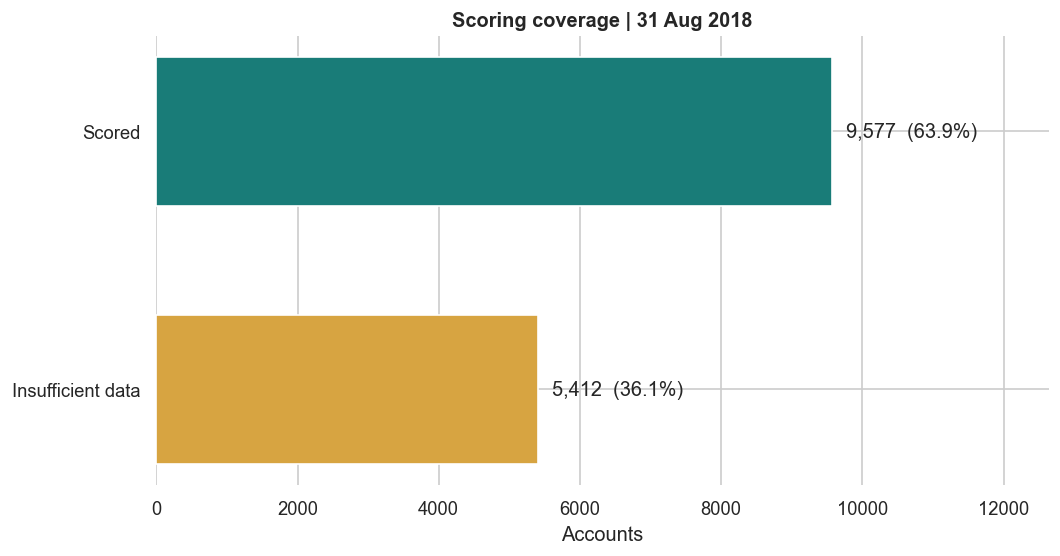

In [3]:
coverage = pd.Series({'Scored': len(eligible), 'Insufficient data': len(not_scored)})
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ['#197C78', '#D7A441']
bars = ax.barh(coverage.index, coverage.values, color=colors, height=0.58)
ax.invert_yaxis()
ax.set_title(f'Scoring coverage | {snapshot:%d %b %Y}')
ax.set_xlabel('Accounts')
ax.set_xlim(0, coverage.max() * 1.32)
for bar, value in zip(bars, coverage.values):
    ax.text(value + coverage.max() * 0.02, bar.get_y() + bar.get_height()/2, f'{value:,}  ({value/len(scores):.1%})', va='center')
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## High-risk probability distribution
The dashed line is the current 0.50 display/classification threshold. It is not a natural boundary in risk and can be changed in the model notebook.

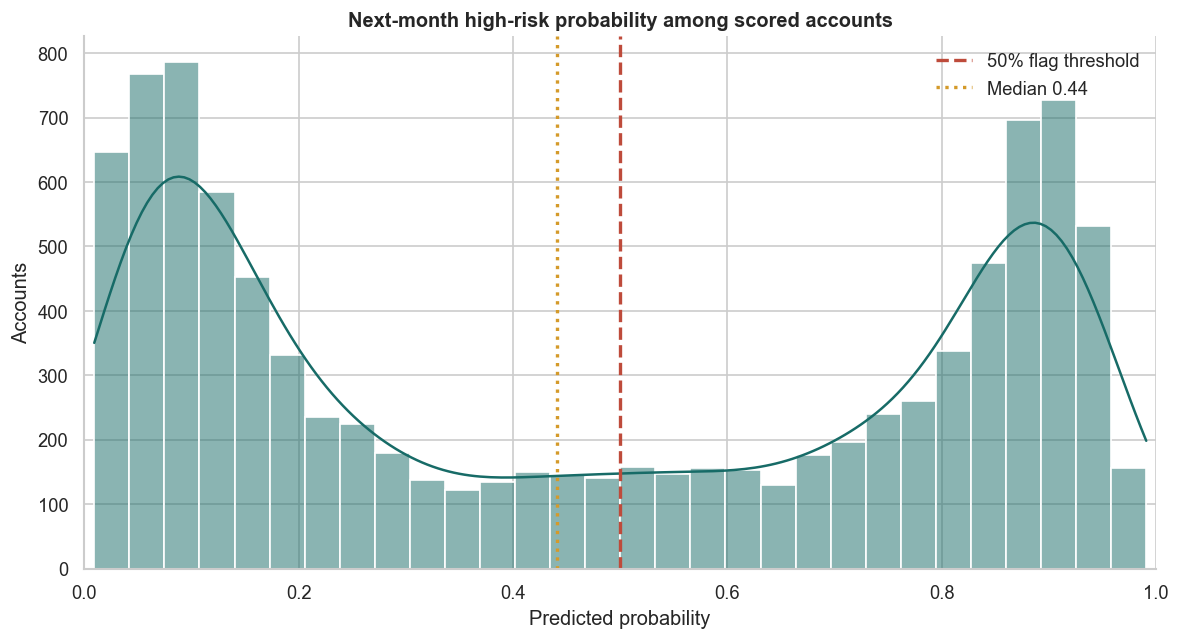

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(eligible['high_risk_probability'], bins=30, kde=True, color='#176B67', edgecolor='white', ax=ax)
ax.axvline(HIGH_RISK_THRESHOLD, color='#BE4B3B', linestyle='--', linewidth=2, label=f'{HIGH_RISK_THRESHOLD:.0%} flag threshold')
ax.axvline(eligible['high_risk_probability'].median(), color='#D49A2A', linestyle=':', linewidth=2, label=f'Median {eligible.high_risk_probability.median():.2f}')
ax.set(title='Next-month high-risk probability among scored accounts', xlabel='Predicted probability', ylabel='Accounts')
ax.set_xlim(0, 1)
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

## Churn and loss components
These are separate classifier probabilities, not components that sum to high-risk probability. The paired scatter helps show whether accounts are predicted at risk primarily through churn, order-value loss, or both.

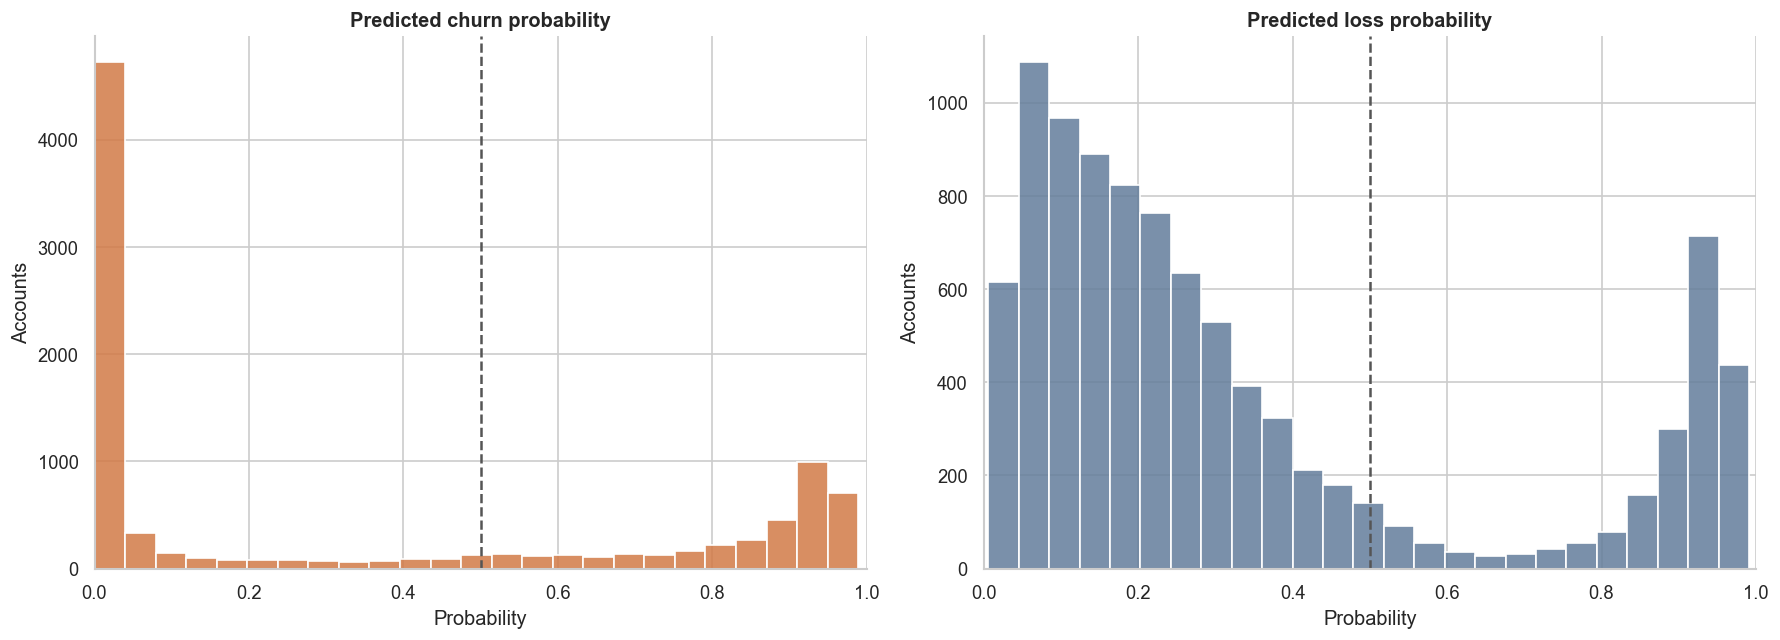

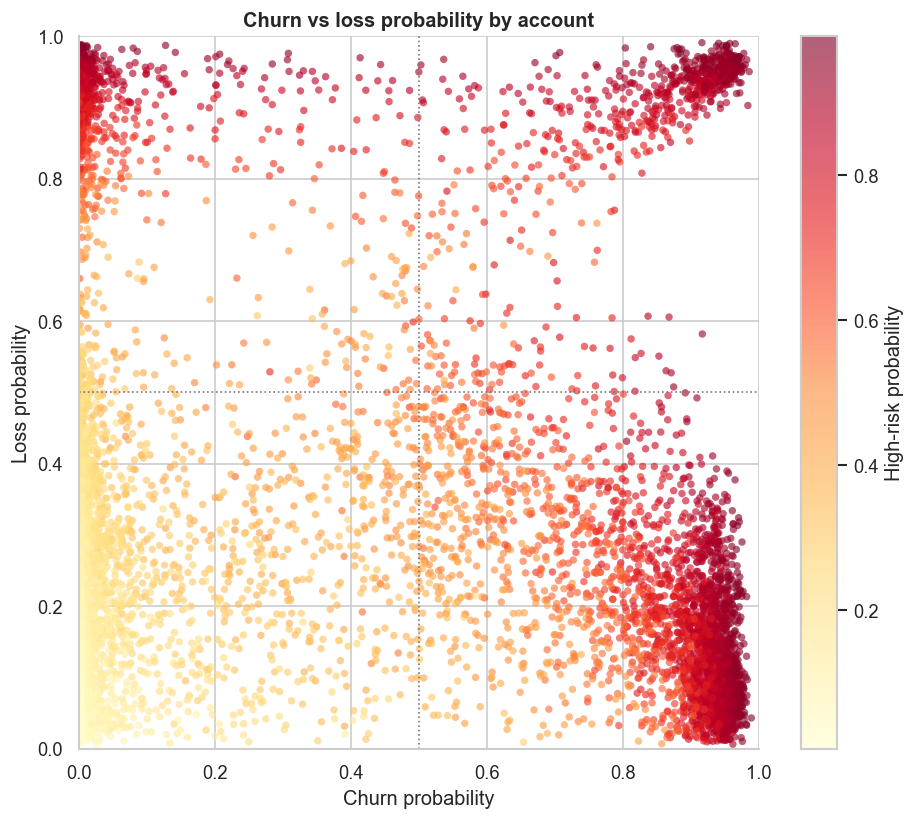

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.histplot(eligible['churn_probability'], bins=25, color='#D27A46', alpha=0.85, ax=axes[0])
axes[0].axvline(0.5, color='#555555', linestyle='--', linewidth=1.5)
axes[0].set(title='Predicted churn probability', xlabel='Probability', ylabel='Accounts', xlim=(0, 1))
sns.histplot(eligible['loss_probability'], bins=25, color='#637D9B', alpha=0.85, ax=axes[1])
axes[1].axvline(0.5, color='#555555', linestyle='--', linewidth=1.5)
axes[1].set(title='Predicted loss probability', xlabel='Probability', ylabel='Accounts', xlim=(0, 1))
sns.despine()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
points = ax.scatter(eligible['churn_probability'], eligible['loss_probability'], c=eligible['high_risk_probability'], cmap='YlOrRd', s=20, alpha=0.62, linewidths=0)
ax.axvline(0.5, color='#777777', linestyle=':', linewidth=1)
ax.axhline(0.5, color='#777777', linestyle=':', linewidth=1)
ax.set(title='Churn vs loss probability by account', xlabel='Churn probability', ylabel='Loss probability', xlim=(0, 1), ylim=(0, 1))
colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label('High-risk probability')
sns.despine()
plt.tight_layout()
plt.show()

## Risk and account importance
Account importance is the revenue percentile. Priority applies the agreed uplift to risk probability. The plot shows the portfolio trade-off; the upper-right area contains accounts that are both relatively important and high risk.

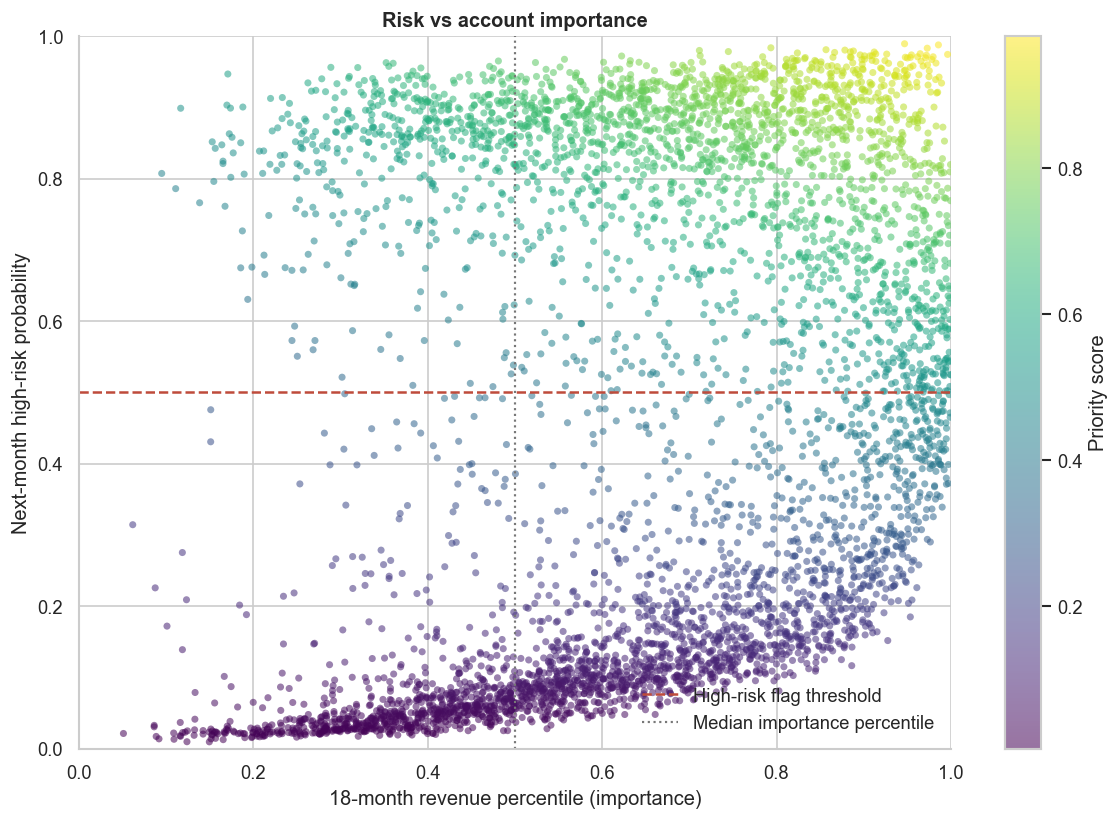

In [6]:
sample = eligible.sample(n=min(5000, len(eligible)), random_state=42) if len(eligible) > 5000 else eligible
fig, ax = plt.subplots(figsize=(10, 7))
points = ax.scatter(sample['account_importance_score'], sample['high_risk_probability'], c=sample['priority_score'], cmap='viridis', s=18, alpha=0.55, linewidths=0)
ax.axhline(HIGH_RISK_THRESHOLD, color='#BE4B3B', linestyle='--', linewidth=1.5, label='High-risk flag threshold')
ax.axvline(0.5, color='#777777', linestyle=':', linewidth=1.3, label='Median importance percentile')
ax.set(title='Risk vs account importance', xlabel='18-month revenue percentile (importance)', ylabel='Next-month high-risk probability', xlim=(0, 1), ylim=(0, 1))
colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label('Priority score')
ax.legend(frameon=False, loc='lower right')
sns.despine()
plt.tight_layout()
plt.show()

## Risk bands and likely issue type
Bands summarize how many scored accounts sit at different probability levels. Mean component probabilities are descriptive within each band; they are not observed churn/loss rates.

,risk_band,accounts,mean_high_risk,mean_churn,mean_loss
0,0-20%,3498,0.093,0.009,0.161
1,20-40%,1099,0.284,0.134,0.312
2,40-60%,907,0.501,0.506,0.365
3,60-80%,1185,0.713,0.602,0.472
4,80-100%,2888,0.890,0.690,0.496


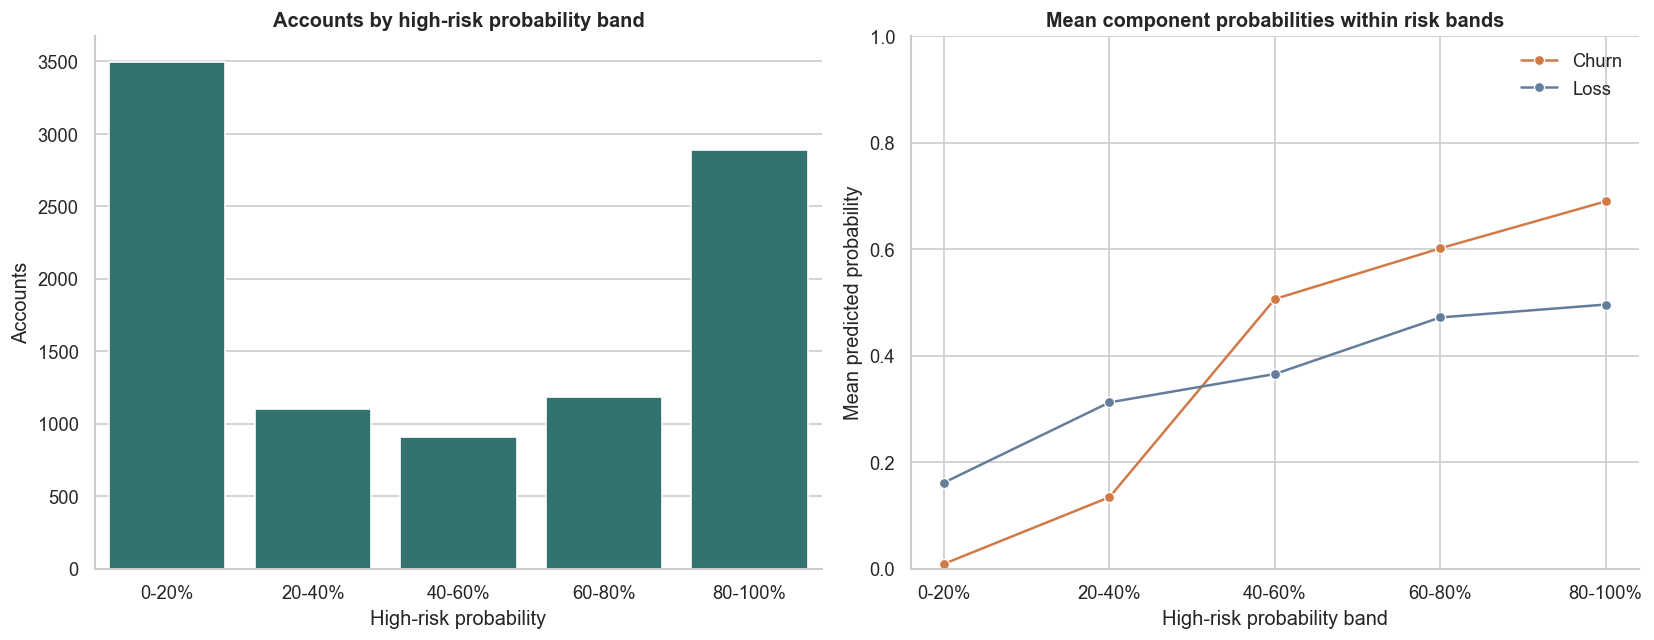

In [7]:
band_summary = eligible.groupby('risk_band', observed=False).agg(
    accounts=('account_id', 'size'),
    mean_high_risk=('high_risk_probability', 'mean'),
    mean_churn=('churn_probability', 'mean'),
    mean_loss=('loss_probability', 'mean'),
).reset_index()
display(band_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(data=band_summary, x='risk_band', y='accounts', color='#287C78', ax=axes[0])
axes[0].set(title='Accounts by high-risk probability band', xlabel='High-risk probability', ylabel='Accounts')
sns.lineplot(data=band_summary, x='risk_band', y='mean_churn', marker='o', label='Churn', color='#D27A46', ax=axes[1])
sns.lineplot(data=band_summary, x='risk_band', y='mean_loss', marker='o', label='Loss', color='#637D9B', ax=axes[1])
axes[1].set(title='Mean component probabilities within risk bands', xlabel='High-risk probability band', ylabel='Mean predicted probability', ylim=(0, 1))
axes[1].legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

## What drives the current high-risk scores?
Global gain ranks features across the model. Local contributions describe the direction and magnitude of a feature's effect for a particular account. These are model explanations, not causal findings.

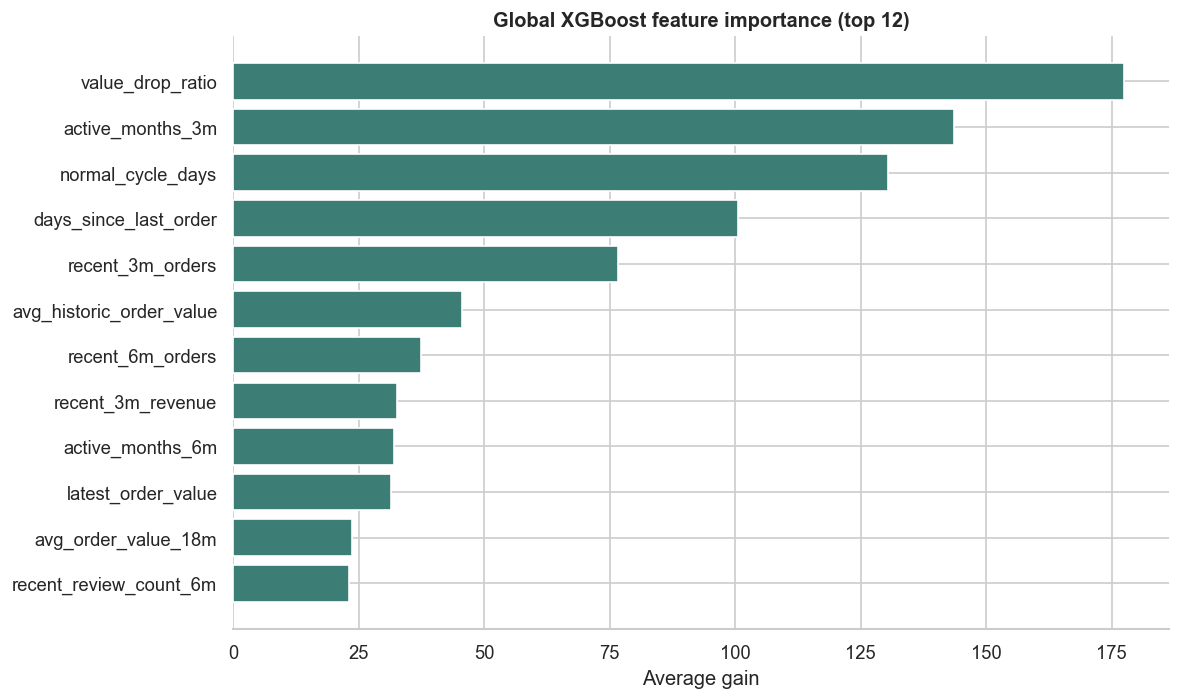

,feature,mean_absolute_contribution,share_increases_risk
11,normal_cycle_days,0.899,0.366
6,days_since_last_order,0.657,0.517
21,value_drop_ratio,0.638,0.194
5,avg_order_value_18m,0.151,0.520
4,avg_historic_order_value,0.114,0.380
14,recent_3m_revenue,0.085,0.410
13,recent_3m_orders,0.082,0.421
7,latest_order_value,0.050,0.309
9,max_order_value_18m,0.044,0.476
17,revenue_drop_ratio_3m,0.043,0.488


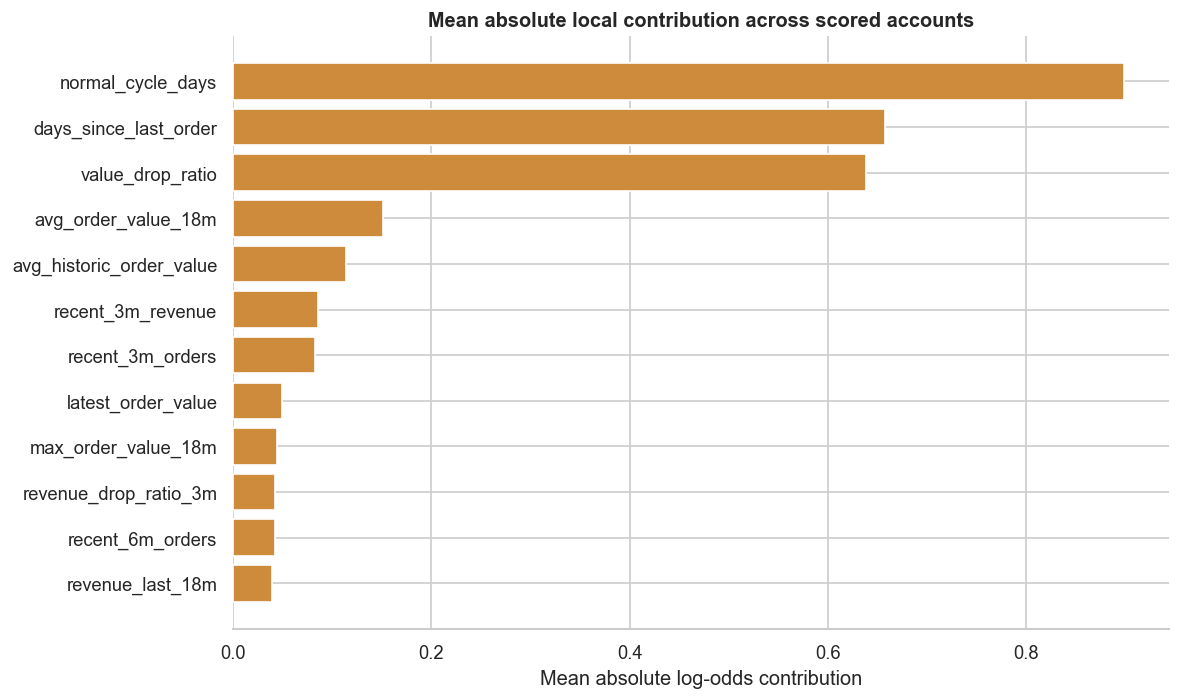

In [8]:
if GLOBAL_IMPORTANCE_PATH.exists():
    global_importance = pd.read_csv(GLOBAL_IMPORTANCE_PATH).sort_values('average_gain', ascending=False).head(12)
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_data = global_importance.sort_values('average_gain')
    ax.barh(plot_data['feature'], plot_data['average_gain'], color='#3C7D75')
    ax.set(title='Global XGBoost feature importance (top 12)', xlabel='Average gain', ylabel='')
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

if LOCAL_CONTRIBUTION_PATH.exists():
    local = pd.read_csv(LOCAL_CONTRIBUTION_PATH)
    local_summary = (
        local.assign(absolute_contribution=local['contribution_log_odds'].abs())
        .groupby('feature', as_index=False)
        .agg(mean_absolute_contribution=('absolute_contribution', 'mean'),
             share_increases_risk=('contribution_direction', lambda s: (s == 'increases_risk').mean()))
        .sort_values('mean_absolute_contribution', ascending=False)
        .head(12)
    )
    display(local_summary.round(3))
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_data = local_summary.sort_values('mean_absolute_contribution')
    ax.barh(plot_data['feature'], plot_data['mean_absolute_contribution'], color='#CE8B3C')
    ax.set(title='Mean absolute local contribution across scored accounts', xlabel='Mean absolute log-odds contribution', ylabel='')
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()
else:
    print(f'{LOCAL_CONTRIBUTION_PATH} not found; skipping local contribution summary.')

## Accounts at the top of the priority queue
The table is a quick review aid. Inspect account explanations before recommending an action; the rank is a prioritisation aid, not an autonomous decision.

In [9]:
display(
    eligible.sort_values('priority_rank')[[
        'priority_rank', 'account_id', 'high_risk_probability',
        'churn_probability', 'loss_probability',
        'account_importance_score', 'priority_score',
        'risk_driver_1', 'risk_driver_2', 'risk_driver_3',
    ]].head(20).round(3)
)

,priority_rank,account_id,high_risk_probability,churn_probability,loss_probability,account_importance_score,priority_score,risk_driver_1,risk_driver_2,risk_driver_3
0,1.0,A37550,0.988,0.989,0.043,0.986,0.981,days_since_last_order,normal_cycle_days,revenue_drop_ratio_3m
1,2.0,A23953,0.991,0.965,0.989,0.969,0.975,days_since_last_order,value_drop_ratio,avg_order_value_18m
2,3.0,A17506,0.974,0.883,0.982,0.996,0.973,value_drop_ratio,avg_order_value_18m,days_since_last_order
3,4.0,A22775,0.983,0.982,0.033,0.973,0.970,days_since_last_order,normal_cycle_days,revenue_last_18m
4,5.0,A35340,0.978,0.804,0.983,0.982,0.969,value_drop_ratio,avg_order_value_18m,days_since_last_order
5,6.0,A04559,0.974,0.005,0.987,0.982,0.965,value_drop_ratio,avg_order_value_18m,avg_historic_order_value
6,7.0,A89114,0.978,0.003,0.988,0.975,0.965,value_drop_ratio,avg_order_value_18m,avg_historic_order_value
7,8.0,A09750,0.980,0.977,0.221,0.967,0.964,days_since_last_order,avg_order_value_18m,normal_cycle_days
8,9.0,A76829,0.989,0.957,0.990,0.947,0.963,days_since_last_order,value_drop_ratio,avg_order_value_18m
9,10.0,A03813,0.981,0.941,0.990,0.961,0.961,days_since_last_order,avg_order_value_18m,value_drop_ratio
